# Gradient Descent: Closed-form Solution and Gradient Descent for Linear Regression

Implement and compare the closed-form solution and gradient descent for simple linear regression with batch gradient descent. 

- Introduce the theoretical background of the closed-form solution as well as the gradient descent algorithm.
- Track the evolution of the estimated slope and intercept over iterations of gradient descent, and compare it to the closed-form solution. 
- Visualize the loss function and the path taken by gradient descent in the parameter space. 
- Explore the effect of different learning rates on convergence.
- Introduce SGD and mini-batch gradient descent.

## Contents

1. [Data](#data)
2. [Simple Linear Regression](#simple-linear-regression)
3. [Multiple Linear Regression](#multiple-linear-regression)
4. [Closed-Form Solution: Advantages and Limitations](#closed-form-solution-for-linear-regression-advantages-and-limitations)
5. [Gradient Descent](#gradient-descent)
   - [Gradient descent implementation](#gradient-descent-implementation)
6. [Visualization and Experimentation](#visualization-and-experimentation)
   - [Plot gradient descent convergence](#plot-gradient-descent-convergence)
   - [Animation](#animation)
   - [Comparing learning rates](#comparing-learning-rates)
7. [Stochastic and Mini-batch Stochastic Gradient Descent](#stochastic-and-mini-batch-stochastic-gradient-descent)
8. [Exercises](#exercises)
   - [Implement your own LinearRegression class](#implement-your-own-linearregression-class)
9. [Takeaways](#takeaways)

We need to fit the function 
$ \hat{y} = xa + b $
so to minimize the mean squared error.

### Data
We generate a synthetic dataset with $n=50$ examples and $m=1$ feature, using known parameters $a$ and $b$ and adding Gaussian noise. 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.set_printoptions(precision=2)

# For animation
from IPython.display import display, clear_output

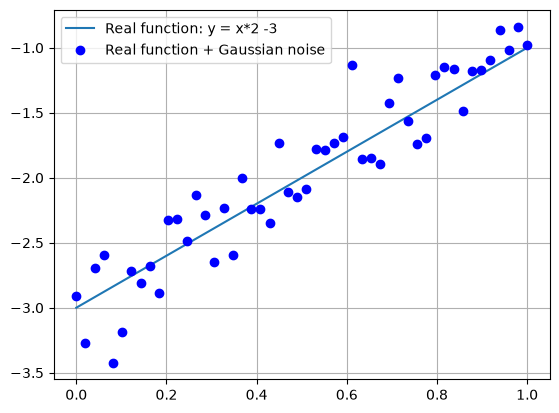

In [3]:
# Synthetic data generation with Gaussian noise
# y = x*a + b + Gaussian noise
# _______________________________________________

# Parameters of the real function
real_a = 2              # real slope
real_b = -3             # real intercept

# Data
n_examples = 50                 # number of examples; this dataset has one feature
# Generate n_examples values of the single feature x from 0 to 1
m_features = 1
data_x = np.linspace(0, 1, n_examples).reshape(n_examples, m_features) # reshape to (n_examples, m_features)

real_y = data_x[:, 0] * real_a + real_b
rng = np.random.default_rng(42)
data_y = real_y + rng.normal(0, 0.3, n_examples)

# Plot the "real" line from (0, real_b) to (1, real_b + real_a)
plt.plot([0, 1], [real_b, real_b + real_a], label=f"Real function: y = x*{real_a} {real_b:+}")

# Plot the (noisy) data points
plt.plot(data_x[:, 0], data_y, 'bo', label = "Real function + Gaussian noise")
# add grid
plt.grid()

plt.legend()

### Simple Linear Regression

The equation of a simple linear regression line is given by:

$ \hat{y} = xa + b $ 

Where:
- $ \hat{y} $ is the predicted target value; $y$ is the observed target.
- $ x $ is the single feature value for one example.
- $ a $ is the slope of the line.
- $ b $ is the y-intercept.

#### Direct formula: Slope ($ a $):
The slope ($ a $) of the regression line can be calculated directly using the following formula:

$$ a = \frac{n(\sum xy) - (\sum x)(\sum y)}{n(\sum x^2) - (\sum x)^2} $$

Where:
- $ n $ is the number of data points.
- $ \sum xy $ is the dot product of $x$ and $y$ (sum of the products of corresponding $x$ and $y$) values.
- $ \sum x $ is the sum of $ x $ values.
- $ \sum y $ is the sum of $ y $ values.
- $ \sum x^2 $ is the sum of the squares of $ x $ values.

#### Direct formula: Y-Intercept ($ b $):
The y-intercept ($ b $) can be calculated using the following formula:

$$ b = \frac{(\sum y) - a(\sum x)}{n} $$

Where:
- $ \sum y $ is the sum of $ y $ values.
- $ a $ is the slope.
- $ \sum x $ is the sum of $ x $ values.
- $ n $ is the number of data points.

In [4]:
# Linear regression by using the closed-form formula

def calculate_linear_regression(data_x, data_y):
    """calculate_linear_regression(data_x, data_y) -> slope, intercept
    Simple linear regression by using the closed-form formula"""
    x_values = data_x[:, 0]
    n = data_x.shape[0]
    
    # Calculate the necessary sums
    sum_x = np.sum(x_values)
    sum_y = np.sum(data_y) 
    sum_xy = np.dot(x_values, data_y)   #or np.sum(np.multiply(x_values, data_y))
    sum_x_squared = np.sum(np.square(x_values))
    
    # Calculate the slope (a) and intercept (b)
    a = (n * sum_xy - sum_x * sum_y) / (n * sum_x_squared - sum_x**2)  # slope
    b = (sum_y - a * sum_x) / n                      # intercept
    
    return a, b


slope, intercept = calculate_linear_regression(data_x, data_y)
print("Slope (a):", slope)
print("Intercept (b):", intercept)

Slope (a): 2.135707087243254
Intercept (b): -3.0404902344737237



### Multiple Linear Regression

In multiple linear regression, the observed dependent variable ($y$) is modeled using $m$ independent variables ($x_1, x_2, \ldots, x_m$):

$y = x_1w_1 + x_2w_2 + \ldots + x_mw_m + w_0 + \varepsilon$, while the prediction is $\hat{y} = x_1w_1 + x_2w_2 + \ldots + x_mw_m + w_0$.

Here, $y$ is the observed dependent variable and $\hat{y}$ is its prediction. The noise term $\varepsilon$ accounts for variation not captured by the model.

Where:
- $x_1, x_2, \ldots, x_m$ are the independent variables.
- $w_0$ is the $y$-intercept (constant term).
- $w_1, w_2, \ldots, w_m$ are the coefficients for the independent variables.
- $\varepsilon$ is the noise term in the data-generating relationship.

The coefficients ($w_0, w_1, \ldots, w_m$) in multiple linear regression can be calculated using matrix notation. Let $X \in \mathbb{R}^{n \times m}$ contain the feature values, with one row per example. Add a column of ones for the intercept to form the design matrix $\tilde{X}=[\mathbf{1}\;X] \in \mathbb{R}^{n \times (m+1)}$:

$$\tilde{\mathbf{w}} = (\tilde{\mathbf{X}}^T \tilde{\mathbf{X}})^{-1} \tilde{\mathbf{X}}^T \mathbf{y}$$

Where:
- $\tilde{\mathbf{w}} = [w_0, w_1, \ldots, w_m]^T$ is the column vector of coefficients, including the intercept.
- $\tilde{\mathbf{X}}$ is the $n \times (m+1)$ design matrix: rows are examples, the first column contains 1s for the intercept, and the remaining $m$ columns are features.
- $\mathbf{y}$ is the $n$-element column vector of observed target values.

### Closed-Form Solution for Linear Regression: Advantages and Limitations

The **closed-form solution** provides a direct way to compute the optimal parameters for ordinary least-squares linear regression, without iterative optimization.

**Advantages**
- The solution is computed directly.
- **Global optimum:** Finds parameters that minimize the sum of squared errors.
- **Efficient for smaller problems:** Particularly practical when the number of features is moderate.
- **Deterministic:** Produces a reproducible solution for the same data, assuming a unique solution.

**Limitations**
- **Computational cost:** Solving the system becomes expensive when the number of features is very large.
- **Numerical stability:** Highly correlated features can cause numerical difficulties. Stable methods such as QR decomposition or SVD help.
- **Regularization:** L2 regularization (Ridge regression) has a related closed-form solution, while L1 regularization (Lasso) generally requires iterative optimization.
- **Large datasets and online learning:** Iterative methods can be more practical when datasets are very large or data arrives continuously.
- **Applicability:** The closed-form solution is specific to least-squares problems. Models such as logistic regression and neural networks do not have closed-form solutions.

**Next:** Gradient descent provides a flexible alternative that can be applied to many models and loss functions.

*Note:* The inverse-based formula assumes that the columns of the design matrix are linearly independent. In practice, numerical least-squares solvers avoid explicitly computing the inverse and can also handle rank-deficient matrices.

# Gradient Descent

For simple linear regression, each of the $n$ examples has one feature $x_i$ and a target value $y_i$. The predicted value is:

$$\hat{y}_i = x_i a + b$$

Here, $a$ is the slope and $b$ is the intercept. In multiple linear regression, $m$ denotes the number of features; here, $m=1$.

The mean squared error over the $n$ examples is:

$$\text{MSE}(y, \hat{y}) = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Substituting $\hat{y}_i = x_i a + b$ gives:

$$\text{MSE}(y, \hat{y}) = \frac{1}{n} \sum_{i=1}^{n} (y_i - (x_i a + b))^2$$

The partial derivatives of the MSE with respect to $a$ and $b$ are:

$$
\begin{align*}
d_a&=&\frac{\partial \text{MSE}}{\partial a} = \frac{\partial}{\partial a} \left( \frac{1}{n} \sum_{i=1}^{n} (y_i - (x_i a + b))^2 \right) &= 2 \cdot \frac{1}{n} \sum_{i=1}^{n} (y_i - (x_i a + b))(-x_i)
&= -\frac{2}{n} \sum_{i=1}^{n} x_i (y_i - \hat{y}_i) \\
d_b&=&\frac{\partial \text{MSE}}{\partial b} = \frac{\partial}{\partial b} \left( \frac{1}{n} \sum_{i=1}^{n} (y_i - (x_i a + b))^2 \right) &= 2 \cdot \frac{1}{n} \sum_{i=1}^{n} (y_i - (x_i a + b))(-1)
&= -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)
\end{align*}
$$

In the implementation, `da` and `db` are these gradients. Each parameter is updated by stepping in the opposite direction, scaled by `learning_rate`:

$$
\begin{aligned}
d_a &= -\frac{2}{n} \sum_{i=1}^{n} x_i (y_i - \hat{y}_i), &
a &\leftarrow a - \text{learning\_rate} \cdot d_a, \\
d_b &= -\frac{2}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i), &
b &\leftarrow b - \text{learning\_rate} \cdot d_b.
\end{aligned}
$$


Gradient Descent and using the direct formula (normal equation) are two methods to compute linear regression. 

- Gradient Descent can be more practical when there are many features, because the normal equation requires forming and solving a system involving an $m \times m$ matrix. But full-batch Gradient Descent processes all $n$ examples at every iteration, and may need many iterations to converge. Which method is faster depends on the dataset dimensions, convergence, and implementation; for a modest number of features, the normal equation can be a reasonable choice even with many examples.
- Gradient Descent can be used with various cost functions beyond the mean squared error, making it flexible for different regression problems.
- Gradient Descent can be parallelized, allowing for faster computation on parallel architectures.
- One has control over the number of iterations and learning rate, to balance between accuracy and computational resources.

Gradient Descent may be preferred for high-dimensional problems, online learning, or when using memory-efficient iterative updates, and when flexibility in the objective or regularization is important. The best choice depends on the problem and implementation.

## Gradient descent implementation

In [5]:
# Gradient descent algorithm implementation
# ____________________________________________

def gradient_descent(data_x, data_y, iterations=1000, learning_rate=0.05):
    """gradient_descent(data_x, data_y, iterations=1000, learning_rate=0.05) -> slope, intercept
    linear regression by using the gradient descent algorithm"""
    x_values = data_x[:, 0]
    n = data_x.shape[0]
    a, b = 0, 0  # initial values for a and b
    
    for _ in range(iterations):
        # Compute the current error
        y = x_values * a + b      # predicted value: x*a + b
        error =  data_y - y     # vector of differences between predicted and actual
        
        # Compute the gradient using vectorized operations
        da = -2/n * np.dot(error, x_values)
        db = -2/n * np.sum(error)
        
        # Update the slope and intercept
        a = a - da * learning_rate
        b = b - db * learning_rate

    return a, b

# Run gradient descent
slope, intercept = gradient_descent(data_x, data_y)
print("Slope (a):", slope)
print("Intercept (b):", intercept)

Slope (a): 2.1326447520272653
Intercept (b): -3.0388466738928646


<details>
<summary><strong>Gradient descent without vector operations</strong></summary>

```python
def gradient_descent_novec(data_x, data_y, iterations=300, learning_rate=0.1):
    """gradient_descent(data_x, data_y, iterations=300, learning_rate=0.1) -> slope, intercept
    linear regression by using the gradient descent algorithm
    without vector operations"""

    x_values = data_x[:, 0]
    n = data_x.shape[0]
    a, b = 0, 0  # initial values for a and b
    
    for _ in range(iterations):
        # Compute the current error
        y = x_values * a + b      # predicted value: x*a + b
        
        # Accumulate per-example contributions to the gradient
        da = 0
        db = 0
        for i in range(n):           # accumulate gradients over all examples
            da += x_values[i] * (data_y[i] - y[i]) # contribution to the gradient w.r.t. a
            db += data_y[i] - y[i]              # contribution to the gradient w.r.t. b
        da = -2/n * da
        db = -2/n * db
        
        # Update a and b
        a = a - da * learning_rate
        b = b - db * learning_rate
        
    return a, b

# Run gradient descent (version without vector operations)
slope, intercept = gradient_descent_novec(data_x, data_y)
print("Slope (a):", slope)
print("Intercept (b):", intercept)
```

</details>

### Visualization and Experimentation
We will visualize:
- How the loss decreases with the number of iterations
- How the values of the slope ($a$) and the intercept ($b$) converge
- How the linear regression lines progressively fit the data points

We will further experiment with different learning rates to see how they affect convergence and stability.

In [6]:
# The same gradient descent function as above, but also records states for visualization

def gradient_descent_meta(data_x, data_y, iterations=300, learning_rate=0.1):
    """Return final parameters and histories from initialization through the final update.

    Each history has iterations + 1 entries, indexed from update 0.
    """
    x_values = data_x[:, 0]
    n = data_x.shape[0]
    a, b = 0, 0  # initial values for a and b
    ab = []
    loss = []
    
    for _ in range(iterations):
        # Compute the current error
        y = x_values * a + b
        error = data_y - y
        ab.append((a, b))
        loss.append(np.mean(error**2))

        # Compute the gradient
        da = -2 / n * np.dot(error, x_values)
        db = -2 / n * np.sum(error)

        # Update the slope and intercept
        a -= da * learning_rate
        b -= db * learning_rate

    # Record the final state after the last update
    ab.append((a, b))
    loss.append(np.mean((data_y - (x_values * a + b))**2))

    return a, b, ab, loss

slope, intercept, ab, loss = gradient_descent_meta(data_x, data_y)
print("Slope (a):", slope)
print("Intercept (b):", intercept)

Slope (a): 2.0887279593586685
Intercept (b): -3.015276455684548


### Plot gradient descent convergence
We plot the values of the loss (MSE) as well as the parameters $a$ and $b$ of $y = xa+b$ over the iterations (parameter updates) to visualize how they converge.

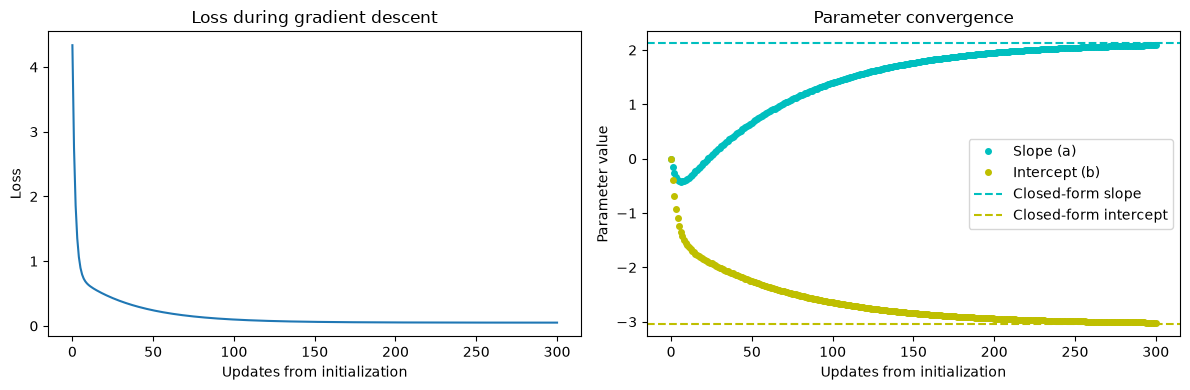

In [7]:
# Plot the loss and parameter values for each parameter update
# ______________________________________________________________

# run the gradient descent with meta data collection
a, b, ab, loss = gradient_descent_meta(data_x, data_y)

# Plot the loss and parameter values at initialization and after each update
df = pd.DataFrame(ab, columns=["a", "b"])
closed_form_a, closed_form_b = calculate_linear_regression(data_x, data_y)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(range(len(loss)), loss)
ax1.set_xlabel("Updates from initialization")
ax1.set_ylabel("Loss")
ax1.set_title("Loss during gradient descent")

ax2.plot(df.index, df["a"], "co", markersize=4, label="Slope (a)")
ax2.plot(df.index, df["b"], "yo", markersize=4, label="Intercept (b)")
ax2.axhline(closed_form_a, color="c", linestyle="--", label="Closed-form slope")
ax2.axhline(closed_form_b, color="y", linestyle="--", label="Closed-form intercept")
ax2.set_xlabel("Updates from initialization")
ax2.set_ylabel("Parameter value")
ax2.set_title("Parameter convergence")
ax2.legend()

plt.tight_layout()
plt.show()

#df

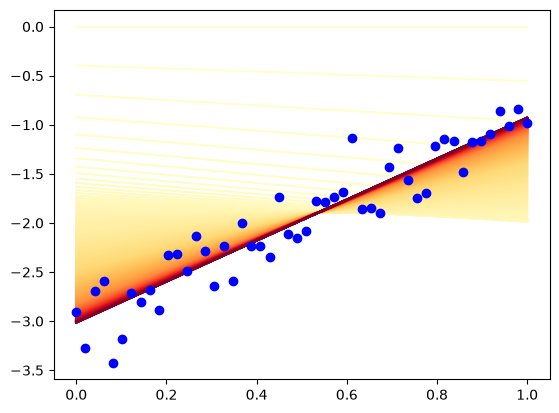

In [8]:
# Plot linear regression lines at each parameter update
# _____________________________________________________

# Create the figure and axes
fig, ax = plt.subplots()

colors = plt.cm.YlOrRd(np.linspace(0, 1, len(ab)))

for index, (a, b) in enumerate(ab):
    plt.plot([0, 1], [b, a + b], color=colors[index])      # Plot the line for a specific a and b
plt.plot(data_x[:, 0], data_y, 'bo', label = "Data")   # Plot the data points

plt.show()


### Animation


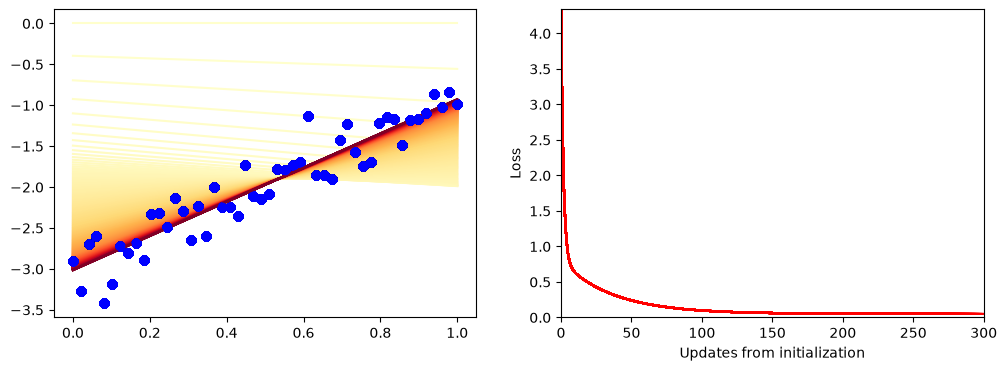

In [11]:
# Animation of the gradient descent process
# ___________________________________________
iterations = 300
a,b,ab,loss = gradient_descent_meta(data_x, data_y, iterations, learning_rate=0.1)

# Create two figures side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(data_x[:, 0], data_y, 'bo', label="Data")

# Create a colormap from yellow to red
colors = plt.cm.YlOrRd(np.linspace(0, 1, len(ab)))

# Function to update the plot for each animation frame
def update(frame):
    if frame < len(ab):
        a, b = ab[frame]
        color = colors[frame]  # Get color from the colormap
        ax1.plot([0, 1], [b, a + b], color=color)
        ax1.plot(data_x[:, 0], data_y, 'bo', label="Data")  # Plot blue dots on top of lines
        ax2.plot(list(range(frame + 1)), loss[:frame + 1], 'r-', label="Loss")
        ax2.set_xlabel("Updates from initialization")
        ax2.set_ylabel("Loss")
        ax2.set_xlim(0, iterations)  # Keep the x-axis consistent across frames
        ax2.set_ylim(0, max(loss))  # Keep the y-axis consistent across frames
        plt.draw()
        clear_output(wait=True)  # Clear the previous output for a clean animation
        display(fig)  # Display the updated figure

# Run the animation
for i in range(len(ab)):
    update(i)
plt.close(fig)   # Close the figure after all lines are plotted



### Comparing learning rates

**Predict:** Which learning rate will reduce the MSE fastest? What do you expect a rate that is too large to do? Try it out and see what happens.

Compare the MSE after each parameter update. The logarithmic y-axis makes both steady decreases and rapid increases visible.

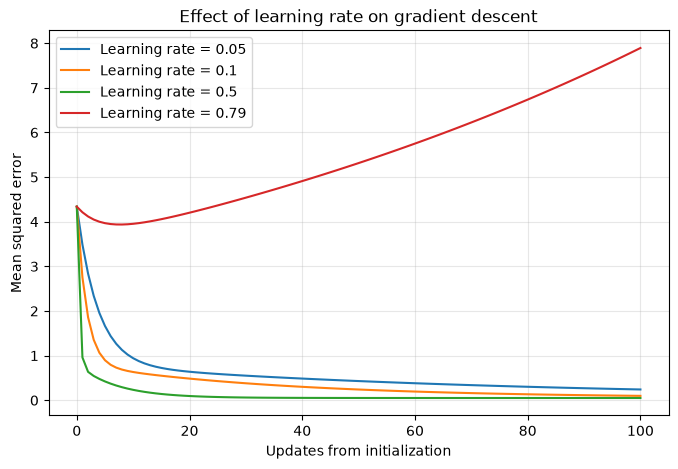

In [20]:
# Plot the effect of different learning rates on the convergence of gradient descent
# ____________________________________________________________________________________
learning_rates = [0.05, 0.1, 0.5, 0.79]
iterations = 100

fig, ax = plt.subplots(figsize=(8, 5))
for rate in learning_rates:
    _, _, _, mse = gradient_descent_meta(
        data_x, data_y, iterations=iterations, learning_rate=rate
    )
    ax.plot(range(iterations + 1), mse, label=f"Learning rate = {rate}")

ax.set_xlabel("Updates from initialization")
ax.set_ylabel("Mean squared error")
ax.set_title("Effect of learning rate on gradient descent")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Stochastic and Mini-batch Stochastic Gradient Descent
In **Batch Gradient Descent**, one iteration (one parameter update) processes the entire training set, so each iteration is one epoch. An epoch means one complete pass through the training data. 

**Stochastic Gradient Descent (SGD)** updates the parameters using one example at a time. Each update is cheap compared to a full-batch update, but noisier because it is based on only one data point at a time. 

**Mini-batch SGD** uses a small, predefined batch size.
 
Cheaper updates do not guarantee shorter total training time: that also depends on how many updates or epochs are needed to converge and on the implementation.

### Mini-Batch Training and Adam

- **Mini-batch training** is the standard approach for training neural networks. It combines frequent weight updates with efficient computation, particularly on GPUs.
- Common batch sizes are 32, 64, 128, and 256.
- **Adam** is an optimization algorithm that determines how model weights are updated using the computed gradients.
- Unlike standard SGD, Adam uses information from previous gradients to adapt the updates for individual parameters.
- **Mini-batching and Adam are complementary:** Mini-batching determines how gradients are computed; Adam determines how weights are updated.

## Exercises: 

1. Multiply all feature values by 10. How does this change the convergence of gradient descent? Does the same learning rate still work?
2. Change the learning rate and observe how it affects convergence. What happens if the learning rate is too high or too low?
3. Implement mini-batch gradient descent and compare its convergence with batch gradient descent. Experiment with different batch sizes and observe how they affect the convergence speed and stability.
4. Implement batch gradient descent for linear regression with (n) examples and two features. 
$$ \hat y = x_1 \cdot a_1 + x_2 \cdot a_2 + b$$
5. Implement your own LinearRegression class (see details below) by using the gradient descent function and compare the result with Scikit's LinearRegression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html


#### Implement your own LinearRegression class

<details>
<summary><strong>Hint: scikit-learn estimator API</strong></summary>

Implement these three methods: `__init__` stores the constructor parameters unchanged; `fit(X, y)` learns and stores the model parameters and returns `self`; `predict(X)` returns predictions for the supplied examples.

```python
# 1. Implement your own LinearRegression class by using the gradient descent algorithm in Scikit-learn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import LinearRegression

class MyLinearRegression(BaseEstimator, RegressorMixin):
    def __init__(self, iterations=1000, learning_rate=0.05):
        '''The init function saves the parameters into member attributes (self....))'''
        pass
    
    def fit(self, data_x, data_y):
        '''The fit function calculates the slope and intercept by using the gradient descent algorithm. 
        It saves the values into member attributes (self.b and self.a) so that the predict function can use them.'''
        pass
                  
    def predict(self, data_x):
        '''The predict function calculates the predicted values for the given data_x by using the slope and intercept. 
        It returns the predictions as a numpy array.'''
        pass
    
# 2. Compare with the Scikit-learn LinearRegression
print("\nMyLinearRegression")
# initialize the class
# fit the data
# print the slope and intercept

print("\nScikit-learn LinearRegression")
# initialize the class
# fit the data
# print the slope and intercept
```
</details>

<details>
<summary><strong>Solution: Implement your own LinearRegression class</strong></summary>
```python
# MyLinearRegression class
class MyLinearRegression(BaseEstimator, RegressorMixin):
    def __init__(self, iterations=1000, learning_rate=0.05):
        self.iterations = iterations
        self.learning_rate = learning_rate
        self.a = 0
        self.b = 0

    def fit(self, data_x, data_y):
        self.a, self.b = gradient_descent(
            data_x, data_y, self.iterations, self.learning_rate
        )
        return self

    def predict(self, data_x):
        return data_x[:, 0] * self.a + self.b

# Compare with scikit-learn's LinearRegression
print("\nMyLinearRegression")
my_lr = MyLinearRegression()
my_lr.fit(data_x, data_y)
print("Slope (a):", my_lr.a)
print("Intercept (b):", my_lr.b)

print("\nScikit-learn LinearRegression")
sk_lr = LinearRegression()
sk_lr.fit(data_x, data_y)
print("Slope (a):", sk_lr.coef_[0])
print("Intercept (b):", sk_lr.intercept_)
```

</details>

## Takeaways

- The direct formula gives the closed-form least-squares solution; gradient descent iteratively minimizes the same mean squared error.
- After a fixed number of updates, gradient descent may not yet be close to the closed-form solution. How close it gets depends on both the learning rate and the number of iterations.
- The **learning rate** is a crucial hyperparameter that affects if and how quickly gradient descent converges.
-  **Batch gradient descent** uses all examples for each update; **Stochastic gradient descent** uses one example at a time; **Mini-batch gradient descent** uses a small random subset of examples for each update. 
- An **epoch** is a complete pass through the entire training dataset.